# Ztracker: square open-field occupancy and swim bouts by genotype

Compare **positive** and **negative** fish across pre / LED / post sessions.
Quarter 1 is the target: `x < 0.5, y < 0.5` in normalized VR coordinates.

In **FISH_DATA**, each integer Fish ID has a `genotype` and three `files`
ordered as pre, LED, post. Your four existing fish IDs and file addresses
are retained. Replace each `None` genotype with `"positive"` or `"negative"`;
their true labels were not supplied and are never inferred from the fish ID.
Add more fish using the same format. Fish IDs must be unique across groups.

The output dictionaries include a **Genotype** column for both summaries
and individual bouts. All Seaborn plots use `hue="Genotype"`: faint lines
pair sessions within fish, thick lines show genotype means with SEM, and
points show individual observations. Means and errors use fish as replicates.

Run cells from top to bottom after assigning labels. The acquisition analysis
is embedded in this notebook; no separate Ztracker module or `zfish` package
is required. Use Python 3.10+ with numpy, pandas, h5py, matplotlib, and
Seaborn 0.13+ (which supports `errorbar="se"`). Saved outputs were cleared
so old plots are not confused with the genotype comparison. No experimental
`res.h5` files were attached here; the updated workflow is checked on synthetic
recordings rather than the E: drive paths on your computer.


In [1]:
from __future__ import annotations

from collections.abc import Mapping, Sequence
from numbers import Integral
from os import PathLike
from pathlib import Path
import warnings

import h5py
import numpy as np


SESSIONS = ("pre", "LED", "post")
QUARTERS = {
    1: "x < 0.5, y < 0.5 (lower-left; target)",
    2: "x >= 0.5, y < 0.5 (lower-right)",
    3: "x < 0.5, y >= 0.5 (upper-left)",
    4: "x >= 0.5, y >= 0.5 (upper-right)",
}


def _text(value):
    if isinstance(value, (bytes, np.bytes_)):
        return value.decode("utf-8", errors="replace").rstrip("\x00")
    return str(value)


def _labels(state, field):
    if field not in state.dtype.names:
        return []
    return sorted({_text(value) for value in state[field]})


def _read_state(path):
    """Read only the controller table; other streams stay on disk."""
    with h5py.File(path, "r") as handle:
        if "state" not in handle:
            raise ValueError(f"{path}: missing numeric 'state' dataset.")
        dataset = handle["state"]
        fields = dataset.dtype.names
        if dataset.ndim != 1 or not fields:
            raise ValueError(f"{path}: 'state' must be a 1-D compound table.")
        required = {"xpos", "ypos"}
        if not required.issubset(fields):
            raise ValueError(f"{path}: missing fields {required - set(fields)}.")
        time_field = next(
            (name for name in ("time_s", "host_time_s") if name in fields),
            None,
        )
        if time_field is None:
            raise ValueError(f"{path}: no publication timestamp field found.")
        selected = [
            name for name in (
                time_field, "assay_time_s", "xpos", "ypos", "assay",
                "environment", "status", "phase", "motion_filled",
                "motion_held", "tracking_fresh", "motion_valid",
                "motion_suppressed", "decoded_this_update", "motion_observed_s",
                "source_stream_id",
            ) if name in fields
        ]
        if "host_time_s" in fields and "host_time_s" not in selected:
            selected.append("host_time_s")
        state = dataset.fields(selected)[:]
        attrs = {key: _text(value) for key, value in handle.attrs.items()}
        lengths = {
            name: len(handle[name]) for name in (
                "state", "states", "frames", "poses", "poses_raw",
                "pose_frame_ids", "pose_host_received_s", "pose_contexts",
            ) if name in handle
        }
    return state, time_field, attrs, lengths, tuple(fields)


def _session_occupancy(
    path, *, time_window, max_gap_s, include_inactive,
    exclude_statuses, exclude_phases,
):
    state, time_field, attrs, lengths, fields = _read_state(path)
    notes = []
    if len(state) < 2:
        raise ValueError(f"{path}: at least two state publications are required.")
    time = np.asarray(state[time_field], dtype=float)
    if not np.all(np.isfinite(time)) or np.any(np.diff(time) < 0):
        raise ValueError(
            f"{path}: nonfinite/backward publication times; inspect the file "
            "before combining clocks or reordering rows."
        )

    # Keep the final publication at a duplicate timestamp. No elapsed time is
    # assigned to duplicates, and no rows from other streams are truncated.
    keep = np.r_[np.diff(time) > 0, True]
    duplicates = int(np.count_nonzero(~keep))
    if duplicates:
        notes.append(f"Kept last row at {duplicates} duplicate timestamp(s).")
    state, time = state[keep], time[keep]
    if len(time) < 2:
        raise ValueError(f"{path}: fewer than two distinct publication times.")
    dt = np.diff(time)

    if include_inactive:
        clock = time - time[0]
        active = np.ones(len(dt), dtype=bool)
        clock_name = f"{time_field} relative to first saved row"
    else:
        if "assay_time_s" not in fields:
            raise ValueError(
                f"{path}: missing assay_time_s. To deliberately include all "
                "saved time, set include_inactive=True."
            )
        clock = np.asarray(state["assay_time_s"], dtype=float)
        if not np.all(np.isfinite(clock)) or np.any(np.diff(clock) < 0):
            raise ValueError(
                f"{path}: nonfinite/backward assay_time_s; inspect clock resets."
            )
        active = np.diff(clock) > 0
        clock_name = "assay_time_s"

    # Host elapsed time is the weight. The active assay clock identifies
    # calibration/paused intervals and optionally clips the analysis window.
    weights = np.where(active, dt, 0.0)
    interval_left, interval_right = time[:-1].copy(), time[1:].copy()
    if time_window is not None:
        start, stop = time_window
        dc = np.diff(clock)
        overlap = np.maximum(
            0.0, np.minimum(clock[1:], stop) - np.maximum(clock[:-1], start)
        )
        fraction = np.divide(
            overlap, dc, out=np.zeros_like(dc), where=dc > 0
        )
        weights *= fraction
        for boundary, target in (
            (start, interval_left), (stop, interval_right)
        ):
            shift = np.divide(
                boundary - clock[:-1], dc,
                out=np.zeros_like(dc), where=dc > 0,
            )
            target[:] = time[:-1] + np.clip(shift, 0, 1) * dt

    # Explicit user exclusions apply at both endpoints, so excluded phases
    # are not bridged. No motion-quality exclusion is applied by default.
    for field, exclusions in (
        ("status", exclude_statuses), ("phase", exclude_phases)
    ):
        if not exclusions:
            continue
        if field not in fields:
            raise ValueError(f"{path}: requested exclusion but no {field} field.")
        excluded = {label.casefold() for label in exclusions}
        allowed = np.array([
            _text(value).casefold() not in excluded for value in state[field]
        ])
        weights *= allowed[:-1] & allowed[1:]

    eligible_time = float(weights.sum())
    large_gap = dt > max_gap_s
    gap_time = float(weights[large_gap].sum())
    x = np.asarray(state["xpos"], dtype=float)
    y = np.asarray(state["ypos"], dtype=float)
    position_ok = (
        np.isfinite(x) & np.isfinite(y)
        & (x >= 0) & (x <= 1) & (y >= 0) & (y <= 1)
    )
    endpoints_ok = position_ok[:-1] & position_ok[1:]
    invalid_time = float(weights[~large_gap & ~endpoints_ok].sum())
    usable = (~large_gap) & endpoints_ok
    dwell_weights = np.where(usable, weights, 0.0)
    valid_time = float(dwell_weights.sum())

    # Left-endpoint sample-and-hold on [t_i, t_{i+1}). The last publication
    # has no known subsequent duration and receives no invented tail time.
    quarter = 1 + (x[:-1] >= 0.5).astype(int)
    quarter += 2 * (y[:-1] >= 0.5).astype(int)
    dwell = np.array([
        dwell_weights[quarter == index].sum() for index in QUARTERS
    ], dtype=float)
    occupancy = dwell / valid_time if valid_time > 0 else np.full(4, np.nan)

    recording_status = attrs.get("status", "unknown")
    if recording_status.casefold() != "complete":
        notes.append(f"Recording status is {recording_status!r}.")
    if attrs.get("error", "").strip() not in ("", "None", "null"):
        notes.append(f"Writer error: {attrs['error']}")
    if "states" in lengths and lengths["states"] != lengths["state"]:
        notes.append("state/states length mismatch; only numeric state was used.")
    pose_lengths = [
        length for name, length in lengths.items()
        if name.startswith("pose")
    ]
    if len(set(pose_lengths)) > 1:
        notes.append("Pose stream lengths differ; poses were not used.")
    if gap_time > 0:
        notes.append(f"Excluded {gap_time:.6g} s in gaps > {max_gap_s:g} s.")
    if invalid_time > 0:
        notes.append(f"Excluded {invalid_time:.6g} s with invalid position endpoints.")
    if valid_time == 0:
        notes.append("No usable duration; occupancy is NaN, not zero.")

    # These describe VR provenance, not independent measurements of movement.
    def quality_fraction(field, invert=False):
        if field not in fields or valid_time == 0:
            return float("nan")
        flag = np.asarray(state[field][:-1], dtype=bool)
        if invert:
            flag = ~flag
        return float(dwell_weights[flag].sum() / valid_time)

    qc = {
        "Analyzed time (s)": valid_time,
        "Eligible time (s)": eligible_time,
        "Gap excluded (s)": gap_time,
        "Invalid position excluded (s)": invalid_time,
        "Time retained": valid_time / eligible_time if eligible_time else np.nan,
        "Filled drive fraction": quality_fraction("motion_filled"),
        "Held drive fraction": quality_fraction("motion_held"),
        "Stale tracking fraction": quality_fraction("tracking_fresh", True),
        "Recording status": recording_status,
        "Schema": attrs.get("schema_version", attrs.get("schema", "unknown")),
        "Assay": "; ".join(_labels(state, "assay")),
        "Environment": "; ".join(_labels(state, "environment")),
        "Statuses": "; ".join(_labels(state, "status")),
        "Phases": "; ".join(_labels(state, "phase")),
        "Time field": time_field,
        "Window clock": clock_name,
        "Time window (s)": repr(time_window),
        "Max gap (s)": max_gap_s,
        "Include inactive": include_inactive,
        "Excluded statuses": "; ".join(exclude_statuses),
        "Excluded phases": "; ".join(exclude_phases),
        "Median state dt (s)": float(np.median(dt)),
        "95th percentile state dt (s)": float(np.quantile(dt, 0.95)),
        "Maximum state dt (s)": float(dt.max()),
        "Duplicate timestamps": duplicates,
        "Dataset lengths": repr(lengths),
        "Available state fields": "; ".join(fields),
        "QC notes": " ".join(notes),
        "File": str(path),
    }
    if notes:
        warnings.warn(f"{path}: {' '.join(notes)}", UserWarning, stacklevel=3)
    context = {
        "state": state, "time": time, "attrs": attrs,
        "original_indices": np.flatnonzero(keep), "lengths": lengths,
        "time_field": time_field, "left": interval_left,
        "right": interval_right, "weights": dwell_weights,
        "quarter": quarter,
    }
    return occupancy, dwell, qc, context


def analyze_occupancy(
    files: Mapping[int, Sequence[str | PathLike]],
    *,
    time_window: tuple[float, float] | None = None,
    max_gap_s: float = 0.5,
    include_inactive: bool = False,
    exclude_statuses: Sequence[str] = (),
    exclude_phases: Sequence[str] = (),
    include_bouts: bool = False,
    max_observation_gap_s: float = 0.15,
    merge_gap_s: float = 0.1,
    return_bouts: bool = False,
) -> dict[str, list] | tuple[dict[str, list], dict[str, list]]:
    """Return equal-length columns for quarter residence time across sessions.

    Parameters
    ----------
    files
        {integer_fish_id: [pre_res_h5, LED_res_h5, post_res_h5]}.
        Session labels follow this input order; they are not inferred from
        LED-request flags, which need not reflect physical light delivery.
    time_window
        Optional (start, stop) in active assay seconds, e.g. (0, 600).
        With include_inactive=True, seconds are relative to the first saved
        publication instead. Boundary intervals are clipped proportionally.
        A file ending before stop contributes only its recorded portion;
        compare 'Analyzed time (s)' to verify equivalent exposure windows.
    max_gap_s
        Inter-publication intervals longer than this are omitted entirely,
        not capped or interpolated. Default 0.5 s is configurable QC, not a
        validated biological threshold. Use np.inf to deliberately retain gaps.
    include_inactive
        False: count only intervals in which assay_time_s advances. This
        omits the frozen initial calibration clock and clock-frozen pauses.
        True: count all publication time, including calibration/paused time.
    exclude_statuses, exclude_phases
        Optional case-insensitive labels read from the actual file, e.g.
        exclude_statuses=("paused",). Inspect returned Statuses/Phases first;
        no version-dependent status vocabulary is assumed.
    include_bouts
        Also reconstruct the saved decoder's swim-active episodes. Prefer
        analyze_behavior() for this combined analysis; see README for the
        observation mask, deduplication, onset allocation and censoring.
    max_observation_gap_s, merge_gap_s
        Maximum gap between real observations (default 0.15 s), and quiet
        gaps shorter than which active episodes are merged (default 0.1 s).
        These are explicit analysis choices, not retrained decoder settings.
    return_bouts
        With include_bouts=True, return (summary_dict, bout_table_dict).
        Otherwise the return value remains a single equal-column dictionary.

    Returns
    -------
    dict
        Equal-length lists; 12 rows per fish (3 sessions x 4 quarters).
        Required columns: Fish ID, Quarter (1--4), Occupancy (fraction),
        Session (pre/LED/post). Also includes dwell time, denominators and QC.
        Occupancies sum to 1 per usable fish/session. A missing quarter has
        occupancy 0; a session with no usable duration has four NaN values.

    Notes
    -----
    Coordinates must already be normalized to [0, 1] in a square open field.
    Exactly 0.5 belongs to the upper/right half; 0 and 1 are valid boundaries.
    Both position endpoints must be finite and in bounds. Stationary periods
    and repeated decoded-frame IDs remain included because this is VR dwell
    time, not a swim count or a tail measurement. Keep raw files unchanged.
    """
    if not isinstance(files, Mapping) or not files:
        raise ValueError("files must be a nonempty {integer: [pre, LED, post]}.")
    if return_bouts and not include_bouts:
        raise ValueError("return_bouts requires include_bouts=True.")
    if include_bouts:
        if not np.isfinite(max_observation_gap_s) or max_observation_gap_s <= 0:
            raise ValueError("max_observation_gap_s must be finite and positive.")
        if not np.isfinite(merge_gap_s) or merge_gap_s < 0:
            raise ValueError("merge_gap_s must be finite and nonnegative.")
    if np.isnan(max_gap_s) or max_gap_s <= 0:
        raise ValueError("max_gap_s must be positive.")
    if time_window is not None:
        if len(time_window) != 2:
            raise ValueError("time_window must contain exactly (start, stop).")
        start, stop = time_window
        if not np.all(np.isfinite([start, stop])) or not 0 <= start < stop:
            raise ValueError("time_window requires finite 0 <= start < stop.")
    for name, labels in (
        ("exclude_statuses", exclude_statuses),
        ("exclude_phases", exclude_phases),
    ):
        if isinstance(labels, str) or any(not isinstance(s, str) for s in labels):
            raise ValueError(f"{name} must be a sequence of strings.")

    # Validate the complete mapping before reading any session.
    inputs = []
    for fish_id, paths in files.items():
        if isinstance(fish_id, bool) or not isinstance(fish_id, Integral):
            raise TypeError(f"Fish ID {fish_id!r} must be an integer.")
        if isinstance(paths, (str, bytes, PathLike)) or len(paths) != 3:
            raise ValueError(f"Fish {fish_id}: provide exactly [pre, LED, post].")
        resolved = [Path(path).expanduser().resolve() for path in paths]
        if len(set(resolved)) != 3:
            raise ValueError(f"Fish {fish_id}: the three session files must differ.")
        for path in resolved:
            if not path.is_file():
                raise FileNotFoundError(path)
        inputs.append((int(fish_id), resolved))

    rows, bout_rows = [], []
    for fish_id, paths in inputs:
        for session, path in zip(SESSIONS, paths):
            occupancy, dwell, qc, context = _session_occupancy(
                path, time_window=time_window, max_gap_s=max_gap_s,
                include_inactive=include_inactive,
                exclude_statuses=exclude_statuses, exclude_phases=exclude_phases,
            )
            bout_summary = {quarter: {} for quarter in QUARTERS}
            if include_bouts:

                bout_summary, events = _analyze_session_bouts(
                    path, context,
                    max_observation_gap_s=max_observation_gap_s,
                    merge_gap_s=merge_gap_s,
                )
                bout_rows.extend({
                    "Fish ID": fish_id, "Session": session,
                    **event, "File": str(path),
                } for event in events)
            for index, quarter in enumerate(QUARTERS):
                rows.append({
                    "Fish ID": fish_id,
                    "Quarter": quarter,
                    "Occupancy": float(occupancy[index]),
                    "Session": session,
                    "Dwell time (s)": float(dwell[index]),
                    "Target": quarter == 1,
                    **qc,
                    **bout_summary[quarter],
                })
    result = {name: [row[name] for row in rows] for name in rows[0]}
    if return_bouts:

        bouts = {name: [row[name] for row in bout_rows] for name in BOUT_COLUMNS}
        return result, bouts
    return result


def analyze_behavior(files, **options):
    """Return occupancy plus swim-bout properties for all fish/quarters.

    Uses the same mapping and occupancy options as analyze_occupancy(). The
    default return value is a dictionary of equal-length lists. Set
    return_bouts=True to also obtain the event-level bout table.
    """
    options["include_bouts"] = True
    return analyze_occupancy(files, **options)


def plot_quarter_metric(result, metric, quarter=1, ax=None):
    """Plot paired fish and their mean for a summary column in one quarter."""
    import matplotlib.pyplot as plt
    import pandas as pd

    table = pd.DataFrame(result)
    wide = table.loc[table["Quarter"] == quarter].pivot(
        index="Fish ID", columns="Session", values=metric,
    ).reindex(columns=SESSIONS)
    if ax is None:
        _, ax = plt.subplots(figsize=(4.4, 4))
    for values in wide.to_numpy():
        ax.plot(range(3), values, "o-", color="0.65", alpha=0.7, lw=1)
    ax.plot(
        range(3), wide.mean(axis=0).to_numpy(), "o-",
        color="#275D8C", lw=2.5, label="Fish mean",
    )
    ax.set(xticks=range(3), xticklabels=SESSIONS,
           ylabel=metric, xlabel="Session", title=f"Quarter {quarter}")
    if not (wide.to_numpy() < 0).any():
        ax.set_ylim(bottom=0)
    ax.spines[["top", "right"]].set_visible(False)
    ax.figure.tight_layout()
    return ax


def plot_target_occupancy(result, ax=None):
    """Plot each fish's target-quarter occupancy and the fish-level mean.

    Returns a matplotlib Axes. NaNs stay as gaps. Gray lines pair sessions
    within fish; the thick line averages fish with data in each session.
    The 25% line is an equal-area reference, not a statistical null model.
    """
    import matplotlib.pyplot as plt
    import pandas as pd

    table = pd.DataFrame(result)
    target = table.loc[table["Quarter"] == 1]
    wide = target.pivot(
        index="Fish ID", columns="Session", values="Occupancy"
    ).reindex(columns=SESSIONS)
    if ax is None:
        _, ax = plt.subplots(figsize=(4.4, 4))
    for values in wide.to_numpy():
        ax.plot(range(3), values * 100, "o-", color="0.65", alpha=0.7, lw=1)
    ax.plot(
        range(3), wide.mean(axis=0).to_numpy() * 100,
        "o-", color="#275D8C", lw=2.5, label="Fish mean",
    )
    ax.axhline(25, color="0.4", ls="--", lw=1, label="Equal-area reference")
    ax.set(xticks=range(3), xticklabels=SESSIONS, ylim=(0, 100),
           ylabel="Target-quarter occupancy (%)", xlabel="Session")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=8)
    ax.figure.tight_layout()
    return ax


In [2]:
"""Reconstruct observed swim bouts without counting held controller values.

Public entry point: ztracker_occupancy.analyze_behavior().
"""

import json
import warnings

import h5py
import numpy as np


BOUT_COLUMNS = (
    "Fish ID", "Session", "Bout ID", "Quarter", "First observed quarter",
    "Onset time (s)", "First active time (s)", "Offset time (s)",
    "Duration (s)", "Left censored", "Right censored", "N observations",
    "Time field", "File",
)
METRIC_COLUMNS = (
    "Swim bout count", "Swim bout rate (per min)",
    "Bout-observable time (s)", "Swim-active time (s)", "Swim fraction",
    "Complete bout count", "Mean bout duration (s)",
    "Left-censored bout fragments", "Right-censored bout fragments",
    "Bout observation coverage",
)
REQUIRED = (
    "decoded_this_update", "tracking_fresh", "motion_valid",
    "motion_held", "motion_filled", "motion_suppressed",
    "motion_observed_s", "source_stream_id",
)


class BoutUnavailable(ValueError):
    """Recording lacks the information required for this measured-bout view."""


def _decode(value):
    return value.decode("utf-8") if isinstance(value, bytes) else str(value)


def _observation_offset(context):
    """Convert absolute host measurement times to the publication time axis."""
    state, time = context["state"], context["time"]
    if context["time_field"] == "host_time_s":
        return 0.0
    if "host_time_s" in state.dtype.names:
        offsets = time - np.asarray(state["host_time_s"], dtype=float)
        if not np.all(np.isfinite(offsets)):
            raise BoutUnavailable("Nonfinite host publication timestamps.")
        offset = float(np.median(offsets))
        if np.max(np.abs(offsets - offset)) > 1e-3:
            raise BoutUnavailable("Host/relative publication clocks disagree.")
        return offset
    origin = context["attrs"].get("host_monotonic_start_s")
    if origin is None:
        raise BoutUnavailable("No host origin for motion_observed_s alignment.")
    return -float(origin)


def _load_observations(path, context):
    """Read matched state JSON in chunks, preserving measurement identity."""
    state, time = context["state"], context["time"]
    missing = set(REQUIRED) - set(state.dtype.names)
    if missing:
        raise BoutUnavailable(f"Missing motion provenance fields: {sorted(missing)}")
    lengths = context["lengths"]
    if "states" not in lengths or lengths["states"] != lengths["state"]:
        raise BoutUnavailable("Matched numeric state and states JSON are required.")
    offset = _observation_offset(context)
    good = (
        state["tracking_fresh"].astype(bool)
        & state["motion_valid"].astype(bool)
        & ~state["motion_held"].astype(bool)
        & ~state["motion_filled"].astype(bool)
        & ~state["motion_suppressed"].astype(bool)
    )
    candidates = np.flatnonzero(good & state["decoded_this_update"].astype(bool))
    originals = context["original_indices"][candidates]
    seen, records, rejected = set(), [], 0
    with h5py.File(path, "r") as handle:
        dataset = handle["states"].asstr()
        for start in range(0, lengths["states"], 1024):
            left, right = np.searchsorted(originals, [start, start + 1024])
            if left == right:
                continue
            chunk = dataset[start:start + 1024]
            for row, original in zip(candidates[left:right], originals[left:right]):
                observed = float(state["motion_observed_s"][row]) + offset
                identity = (_decode(state["source_stream_id"][row]), observed)
                if identity in seen:
                    continue
                seen.add(identity)
                if (
                    not np.isfinite(observed)
                    or observed < time[0] or observed > time[row] + 1e-6
                ):
                    good[row] = False
                    rejected += 1
                    continue
                try:
                    snapshot = json.loads(chunk[original - start])
                    system = snapshot.get("system_state") or {}
                    motion = system.get("motion") or snapshot.get("behavior") or {}
                    active = motion.get("active")
                except (ValueError, AttributeError, TypeError):
                    active = None
                if not isinstance(active, (bool, int)) or active not in (0, 1):
                    good[row] = False
                    rejected += 1
                    continue
                records.append((row, observed, identity[0], bool(active)))
    if len(records) < 2:
        raise BoutUnavailable("Fewer than two usable, distinct motion observations.")
    rows = np.array([record[0] for record in records], dtype=int)
    observed = np.array([record[1] for record in records])
    if np.any(np.diff(observed) <= 0):
        raise BoutUnavailable("Motion times move backward; inspect stream changes.")
    return {
        "rows": rows, "time": observed,
        "stream": np.array([record[2] for record in records]),
        "active": np.array([record[3] for record in records]),
        "good": good, "rejected": rejected,
    }


def _quarter_at(time, context):
    """Backward/as-of position lookup; never use a future publication."""
    index = np.searchsorted(context["time"], time, side="right") - 1
    state = context["state"]
    if index < 0 or index >= len(state):
        return np.nan
    x, y = float(state["xpos"][index]), float(state["ypos"][index])
    if not np.isfinite(x + y) or not (0 <= x <= 1 and 0 <= y <= 1):
        return np.nan
    return 1 + int(x >= 0.5) + 2 * int(y >= 0.5)


def _active_runs(active, time, merge_gap_s):
    """Return active envelopes; merge only observed internal quiet gaps."""
    starts = np.flatnonzero(active & ~np.r_[False, active[:-1]])
    stops = np.flatnonzero(active & ~np.r_[active[1:], False]) + 1
    merged = []
    for start, stop in zip(starts, stops):
        if (
            merged and merged[-1][1] < len(time)
            and time[start] - time[merged[-1][1]] < merge_gap_s - 1e-12
        ):
            merged[-1][1] = int(stop)
        else:
            merged.append([int(start), int(stop)])
    return merged


def _analyze_session_bouts(
    path, context, *, max_observation_gap_s, merge_gap_s,
):
    """Return per-quarter metrics and an explicit table of bout fragments."""
    metadata = {
        "Max observation gap (s)": max_observation_gap_s,
        "Bout merge gap (s)": merge_gap_s,
        "Bout method": "deduplicated saved active; onset quarter; strict QC",
    }
    try:
        observations = _load_observations(path, context)
    except (BoutUnavailable, ValueError) as error:
        message = f"Bout analysis unavailable: {error}"
        warnings.warn(f"{path}: {message}", UserWarning, stacklevel=3)
        return {
            quarter: {
                **{name: np.nan for name in METRIC_COLUMNS},
                "Bout status": message, **metadata,
            } for quarter in range(1, 5)
        }, []

    time, rows = observations["time"], observations["rows"]
    active = observations["active"]
    exposure, active_time = np.zeros(4), np.zeros(4)
    connected = np.zeros(len(time) - 1, dtype=bool)
    bad_prefix = np.r_[0, np.cumsum(~observations["good"])]
    # Each real observation brackets the next real observation. No support is
    # extrapolated before the first or after the last observed measurement.
    for index, (start, stop) in enumerate(zip(time[:-1], time[1:])):
        if stop - start > max_observation_gap_s + 1e-12:
            continue
        if observations["stream"][index] != observations["stream"][index + 1]:
            continue
        if bad_prefix[rows[index + 1] + 1] - bad_prefix[rows[index]]:
            continue
        left = max(0, np.searchsorted(context["time"], start, side="right") - 1)
        right = min(
            len(context["weights"]),
            np.searchsorted(context["time"], stop, side="left"),
        )
        overlap = np.maximum(
            0.0,
            np.minimum(context["right"][left:right], stop)
            - np.maximum(context["left"][left:right], start),
        )
        overlap = np.where(context["weights"][left:right] > 0, overlap, 0)
        # Conservative support: the complete measurement bracket must lie in
        # the selected, valid VR interval set, including any requested window.
        if not np.isclose(overlap.sum(), stop - start, atol=1e-8, rtol=1e-7):
            continue
        connected[index] = True
        quarter = context["quarter"][left:right]
        for q in range(1, 5):
            duration = overlap[quarter == q].sum()
            exposure[q - 1] += duration
            active_time[q - 1] += duration * active[index]

    cuts = np.r_[0, np.flatnonzero(~connected) + 1, len(time)]
    counts, complete = np.zeros(4, dtype=int), np.zeros(4, dtype=int)
    left_counts, right_counts = np.zeros(4, dtype=int), np.zeros(4, dtype=int)
    durations, events = [[] for _ in range(4)], []
    for first, end in zip(cuts[:-1], cuts[1:]):
        if end - first < 2:
            continue
        segment_time, segment_active = time[first:end], active[first:end]
        runs = _active_runs(segment_active, segment_time, merge_gap_s)
        for run_index, (onset, offset) in enumerate(runs):
            left_censored = onset == 0
            right_censored = offset == len(segment_time)
            if not right_censored and run_index == len(runs) - 1:
                quiet_tail = segment_time[-1] - segment_time[offset]
                right_censored = quiet_tail < merge_gap_s - 1e-12
            onset_time = float(segment_time[onset])
            stop_time = np.nan if right_censored else float(segment_time[offset])
            q = _quarter_at(onset_time, context)
            if not np.isfinite(q):
                continue
            duration = (
                stop_time - onset_time
                if not left_censored and not right_censored else np.nan
            )
            if left_censored:
                left_counts[q - 1] += 1
            else:
                counts[q - 1] += 1
                if not right_censored:
                    complete[q - 1] += 1
                    durations[q - 1].append(duration)
            if right_censored:
                right_counts[q - 1] += 1
            events.append({
                "Bout ID": len(events) + 1,
                "Quarter": np.nan if left_censored else q,
                "First observed quarter": q,
                "Onset time (s)": np.nan if left_censored else onset_time,
                "First active time (s)": onset_time,
                "Offset time (s)": stop_time,
                "Duration (s)": duration,
                "Left censored": bool(left_censored),
                "Right censored": bool(right_censored),
                "N observations": int(min(offset + 1, len(segment_time)) - onset),
                "Time field": context["time_field"],
            })

    dwell = np.array([
        context["weights"][context["quarter"] == q].sum() for q in range(1, 5)
    ])
    usable = exposure.sum() > 0
    status = "ok" if usable else "No continuous usable motion-observation time."
    if observations["rejected"]:
        status += f" Rejected {observations['rejected']} missing/invalid motion rows."
    if not usable:
        warnings.warn(f"{path}: {status}", UserWarning, stacklevel=3)
    metrics = {}
    for index in range(4):
        metrics[index + 1] = {
            "Swim bout count": int(counts[index]) if usable else np.nan,
            "Swim bout rate (per min)": (
                counts[index] / exposure[index] * 60 if exposure[index] else np.nan
            ),
            "Bout-observable time (s)": float(exposure[index]),
            "Swim-active time (s)": float(active_time[index]),
            "Swim fraction": (
                active_time[index] / exposure[index] if exposure[index] else np.nan
            ),
            "Complete bout count": int(complete[index]) if usable else np.nan,
            "Mean bout duration (s)": (
                float(np.mean(durations[index])) if durations[index] else np.nan
            ),
            "Left-censored bout fragments": int(left_counts[index]),
            "Right-censored bout fragments": int(right_counts[index]),
            "Bout observation coverage": (
                float(exposure[index] / dwell[index]) if dwell[index] else np.nan
            ),
            "Bout status": status, **metadata,
        }
    return metrics, events


In [15]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


GENOTYPE_ORDER = ["positive", "negative"]
GENOTYPE_PALETTE = {"positive": "#275D8C", "negative": "#C76850"}


def split_fish_data(fish_data):
    """Validate {fish_id: {'genotype': label, 'files': [pre, LED, post]}}."""
    if not isinstance(fish_data, Mapping) or not fish_data:
        raise ValueError("FISH_DATA must be a nonempty fish dictionary.")
    files, genotypes, unlabeled = {}, {}, []
    for fish_id, entry in fish_data.items():
        if isinstance(fish_id, bool) or not isinstance(fish_id, Integral):
            raise TypeError(f"Fish ID {fish_id!r} must be an integer.")
        if not isinstance(entry, Mapping):
            raise ValueError(f"Fish {fish_id}: provide genotype and files fields.")
        paths = entry.get("files")
        if (
            not isinstance(paths, Sequence)
            or isinstance(paths, (str, bytes, PathLike)) or len(paths) != 3
        ):
            raise ValueError(f"Fish {fish_id}: files must be [pre, LED, post].")
        label = entry.get("genotype")
        if not isinstance(label, str) or label.strip().lower() not in GENOTYPE_ORDER:
            unlabeled.append(fish_id)
            continue
        files[int(fish_id)] = list(paths)
        genotypes[int(fish_id)] = label.strip().lower()
    if unlabeled:
        raise ValueError(
            "Set genotype to 'positive' or 'negative' in FISH_DATA for fish: "
            + ", ".join(map(str, unlabeled))
        )
    return files, genotypes


def add_genotypes(data, genotypes):
    """Attach a fish-level label to every summary/event row without mutation."""
    labels = []
    for fish_id in data["Fish ID"]:
        if fish_id not in genotypes:
            raise ValueError(f"No genotype label supplied for fish {fish_id}.")
        labels.append(genotypes[fish_id])
    result = {key: list(values) for key, values in data.items()}
    result["Genotype"] = labels
    return result


def analyze_by_genotype(fish_data, **options):
    """Run occupancy/bout analysis and add Genotype to all returned tables.

    The default return value is a dictionary of equal-length lists, including
    Fish ID, Genotype, Quarter, Session, Occupancy and swim-bout properties.
    With return_bouts=True, return (summary_dict, bout_event_dict).
    """
    files, genotypes = split_fish_data(fish_data)
    output = analyze_behavior(files, **options)
    if isinstance(output, tuple):
        summary, bouts = output
        return add_genotypes(summary, genotypes), add_genotypes(bouts, genotypes)
    return add_genotypes(output, genotypes)


def plot_genotype_metric(
    data, metric="Occupancy", quarter=1, *, ax=None,
    as_percent=False, show_legend=True,
):
    """Plot per-fish trajectories, genotype means +/- SEM, and observations."""
    frame = pd.DataFrame(data)
    required = {"Fish ID", "Genotype", "Quarter", "Session", metric}
    if not required.issubset(frame):
        raise ValueError(f"Missing plotting columns: {required - set(frame)}")
    frame = frame.loc[frame["Quarter"] == quarter].copy()
    if frame.empty:
        raise ValueError(f"No observations for Quarter {quarter}.")
    if frame["Genotype"].isna().any():
        raise ValueError("Every plotted fish needs a genotype label.")
    if not frame["Genotype"].isin(GENOTYPE_ORDER).all():
        raise ValueError("Genotype must be positive or negative.")
    if frame.groupby("Fish ID")["Genotype"].nunique().gt(1).any():
        raise ValueError("Each Fish ID must have one consistent genotype.")
    if frame.duplicated(["Fish ID", "Session"]).any():
        raise ValueError("Expected one row per fish/session in a quarter.")
    frame["Session"] = pd.Categorical(
        frame["Session"], categories=SESSIONS, ordered=True,
    )
    frame["Genotype"] = pd.Categorical(
        frame["Genotype"], categories=GENOTYPE_ORDER, ordered=True,
    )
    frame = frame.sort_values(["Genotype", "Fish ID", "Session"])
    if as_percent:
        frame[metric] = frame[metric] * 100
    if ax is None:
        _, ax = plt.subplots(figsize=(4, 3))

    hue_options = {
        "hue": "Genotype", "hue_order": GENOTYPE_ORDER,
        "palette": GENOTYPE_PALETTE,
    }
    sns.lineplot(
        data=frame, x="Session", y=metric, units="Fish ID",
        estimator=None, linewidth=0.6, alpha=0.35,
        legend=False, ax=ax, **hue_options,
    )
    sns.lineplot(
        data=frame, x="Session", y=metric,
        estimator="mean", errorbar="se", linewidth=2,
        marker="s", markersize=5, markeredgecolor="none",
        err_style="bars",
        err_kws={"capsize": 3, "linewidth": 2, "capthick": 2},
        legend=show_legend, ax=ax, **hue_options,
    )
    sns.stripplot(
        data=frame, x="Session", y=metric, order=SESSIONS,
        dodge=True, jitter=0.1, alpha=0.7, size=5, linewidth=0,
        legend=False, ax=ax, **hue_options,
    )
    if metric == "Occupancy":
        ax.axhline(25 if as_percent else 0.25, color="0.4", ls="--", lw=0.7)
        #ax.set_ylim(0, 100 if as_percent else 1)
    else:
        ax.set_ylim(bottom=0)
    ax.set(
        xlabel="Session", ylabel=metric + (" (%)" if as_percent else ""),
        title=f"Quarter {quarter}" + (" (target)" if quarter == 1 else ""),
    )
    ax.spines[["top", "right"]].set_visible(False)
    if show_legend:
        ax.legend(title="Genotype", frameon=False)
    return ax


In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Fill genotype with "positive" or "negative" for each fish.
# files must stay ordered as pre, LED, post.
FISH_DATA = {
        10290: {'genotype': "Positive",
                'files': [r'E:\Open Field\Square OF\Dat-CoChr Positive\10290\S3-OF-Pre\res.h5',
                          r'E:\Open Field\Square OF\Dat-CoChr Positive\10290\S4-OF-LED\res.h5',
                          r'E:\Open Field\Square OF\Dat-CoChr Positive\10290\S5-OF-Post\res.h5']},
 10292: {'genotype': "Positive",
         'files': [r'E:\Open Field\Square OF\Dat-CoChr Positive\10292\S3-OF-Pre\res.h5',
                   r'E:\Open Field\Square OF\Dat-CoChr Positive\10292\S4-OF-LED\res.h5',
                   r'E:\Open Field\Square OF\Dat-CoChr Positive\10292\S5-OF-Post\res.h5']},
 10293: {'genotype': "Positive",
         'files': [r'E:\Open Field\Square OF\Dat-CoChr Positive\10293\S3-OF-Pre\res.h5',
                   r'E:\Open Field\Square OF\Dat-CoChr Positive\10293\S4-OF-LED\res.h5',
                   r'E:\Open Field\Square OF\Dat-CoChr Positive\10293\S5-OF-Post\res.h5']},
 10294: {'genotype': "Positive",
         'files': [r'E:\Open Field\Square OF\Dat-CoChr Positive\10294\S3-OF-Pre\res.h5',
                   r'E:\Open Field\Square OF\Dat-CoChr Positive\10294\S4-OF-LED\res.h5',
                   r'E:\Open Field\Square OF\Dat-CoChr Positive\10294\S5-OF-Post\res.h5']},
 10295: {'genotype': "Positive",
         'files': [r'E:\Open Field\Square OF\Dat-CoChr Positive\10295\S3-OF-Pre\res.h5',
                   r'E:\Open Field\Square OF\Dat-CoChr Positive\10295\S4-OF-LED\res.h5',
                   r'E:\Open Field\Square OF\Dat-CoChr Positive\10295\S5-OF-Post\res.h5']},
 10296: {'genotype': "Positive",
         'files': [r'E:\Open Field\Square OF\Dat-CoChr Positive\10296\S3-OF-Pre\res.h5',
                   r'E:\Open Field\Square OF\Dat-CoChr Positive\10296\S4-OF-LED\res.h5',
                   r'E:\Open Field\Square OF\Dat-CoChr Positive\10296\S5-OF-Post\res.h5']},
 10297: {'genotype': "Negative",
         'files': [r'E:\Open Field\Square OF\Dat-CoChr Negative\10297\S3-OF-Pre\res.h5',
                   r'E:\Open Field\Square OF\Dat-CoChr Negative\10297\S4-OF-LED\res.h5',
                   r'E:\Open Field\Square OF\Dat-CoChr Negative\10297\S5-OF-Post\res.h5']},
 10298: {'genotype': "Negative",
         'files': [r'E:\Open Field\Square OF\Dat-CoChr Negative\10298\S3-OF-Pre\res.h5',
                   r'E:\Open Field\Square OF\Dat-CoChr Negative\10298\S4-OF-LED\res.h5',
                   r'E:\Open Field\Square OF\Dat-CoChr Negative\10298\S5-OF-Post\res.h5']},
 10299: {'genotype': "Negative",
         'files': [r'E:\Open Field\Square OF\Dat-CoChr Negative\10299\S3-OF-Pre\res.h5',
                   r'E:\Open Field\Square OF\Dat-CoChr Negative\10299\S4-OF-LED\res.h5',
                   r'E:\Open Field\Square OF\Dat-CoChr Negative\10299\S5-OF-Post\res.h5']},
 10300: {'genotype': "Negative",
         'files': [r'E:\Open Field\Square OF\Dat-CoChr Negative\10300\S3-OF-Pre\res.h5',
                   r'E:\Open Field\Square OF\Dat-CoChr Negative\10300\S4-OF-LED\res.h5',
                   r'E:\Open Field\Square OF\Dat-CoChr Negative\10300\S5-OF-Post\res.h5']},
 10301: {'genotype': "Negative",
         'files': [r'E:\Open Field\Square OF\Dat-CoChr Negative\10301\S3-OF-Pre\res.h5',
                   r'E:\Open Field\Square OF\Dat-CoChr Negative\10301\S4-OF-LED\res.h5',
                   r'E:\Open Field\Square OF\Dat-CoChr Negative\10301\S5-OF-Post\res.h5']},
 10302: {'genotype': "Negative",
         'files': [r'E:\Open Field\Square OF\Dat-CoChr Negative\10302\S3-OF-Pre\res.h5',
                   r'E:\Open Field\Square OF\Dat-CoChr Negative\10302\S4-OF-LED\res.h5',
                   r'E:\Open Field\Square OF\Dat-CoChr Negative\10302\S5-OF-Post\res.h5']}
}

CONFIG = {'max_observation_gap_s': 0.15,
 'merge_gap_s': 0.1,
 'time_window': None,
 'max_gap_s': 0.5,
 'include_inactive': False,
 'exclude_statuses': (),
 'exclude_phases': ()}


## Calculate occupancy

For each consecutive pair of state publications, the left position represents
that interval. Host timestamp differences weight residence time. By default,
only intervals with an advancing assay clock are eligible, omitting frozen
calibration and clock-frozen pauses. Long gaps and invalid position endpoints
are omitted. There is no extrapolation after the last publication.
Held/filled motion inputs and stationary periods remain part of VR residence
time; their quality fractions are reported separately.

Quarter 1: lower-left target; 2: lower-right; 3: upper-left; 4: upper-right.
Coordinates at 0.5 belong to the upper/right half.


In [5]:
result, bouts = analyze_by_genotype(FISH_DATA, return_bouts=True, **CONFIG)
bout_table = pd.DataFrame(bouts)
assert len({len(values) for values in result.values()}) == 1
assert len({len(values) for values in bouts.values()}) == 1

table = pd.DataFrame(result)
for frame in (table, bout_table):
    frame["Session"] = pd.Categorical(
        frame["Session"], categories=SESSIONS, ordered=True,
    )
    frame["Genotype"] = pd.Categorical(
        frame["Genotype"], categories=GENOTYPE_ORDER, ordered=True,
    )
display(table[[
    "Fish ID", "Genotype", "Quarter", "Occupancy", "Session", "Dwell time (s)"
]])


C:\Users\Shuyang Yao\AppData\Local\Temp\ipykernel_48764\738500820.py:406: UserWarning: E:\Open Field\Square OF\Dat-CoChr Positive\10294\S5-OF-Post\res.h5: Recording status is 'incomplete'. Writer error: Tail video writer cannot keep up: 68 frames pending (including in-flight), 255.0/256.0 MiB buffered, codec MJPG. Incoming 26.2 fps; measured write capacity 40.9 fps. Recording stopped explicitly; no frames were silently dropped. A larger queue cannot correct a sustained storage deficit. Use a faster local drive or reduce Camera / simulation rate; run python validations/check_recording.py --save-dir <save_folder> --fps <camera_rate> --seconds 20 on the recording drive.
  return analyze_occupancy(files, **options)


,Fish ID,Genotype,Quarter,Occupancy,Session,Dwell time (s)
0,10290,positive,1,0.251405,pre,452.551022
1,10290,positive,2,0.242701,pre,436.884690
2,10290,positive,3,0.229578,pre,413.261005
3,10290,positive,4,0.276316,pre,497.394081
4,10290,positive,1,0.214088,LED,385.372949
...,...,...,...,...,...,...
139,10302,negative,4,0.233482,LED,373.577650
140,10302,negative,1,0.242786,post,388.465095
141,10302,negative,2,0.260031,post,416.058302
142,10302,negative,3,0.234059,post,374.501900


In [6]:
import pickle

with open('ZTracker Square OF.pkl', 'wb') as f:
    pickle.dump([result, bouts], f)

## Inspect session quality and denominators

Inspect these before comparing sessions. A short recording can close normally
and still end early. A common requested time window does not recover missing
or unrecorded time. Unequal analyzed durations and large missing fractions
should be considered when interpreting occupancy.


In [7]:
qc = table.drop_duplicates(["Fish ID", "Session"])
qc_columns = [
    "Fish ID", "Genotype", "Session", "Recording status", "Schema", "Assay", "Environment",
    "Statuses", "Phases", "Eligible time (s)", "Analyzed time (s)",
    "Gap excluded (s)", "Invalid position excluded (s)", "Time retained",
    "Median state dt (s)", "95th percentile state dt (s)",
    "Filled drive fraction", "Held drive fraction", "Stale tracking fraction",
    "QC notes",
]
display(qc[qc_columns])

# Optional: inspect all saved controller fields and available stream lengths.
display(qc[["Fish ID", "Session", "Available state fields", "Dataset lengths"]])

# Every usable session must sum to 1 across its four quarters.
occupancy_sums = table.groupby(
    ["Fish ID", "Session"], observed=True
)["Occupancy"].sum(min_count=1)
assert np.allclose(occupancy_sums.dropna().to_numpy(), 1)


,Fish ID,Genotype,Session,Recording status,Schema,Assay,Environment,Statuses,Phases,Eligible time (s),Analyzed time (s),Gap excluded (s),Invalid position excluded (s),Time retained,Median state dt (s),95th percentile state dt (s),Filled drive fraction,Held drive fraction,Stale tracking fraction,QC notes
0,10290,positive,pre,complete,15,Square OF-LED,open_field2,Calibrating; Running,continuous; idle,1800.090798,1800.090798,0.0,0.0,1.0,0.023920,0.068625,0.597544,0.597544,0.597563,
4,10290,positive,LED,complete,15,Square OF-LED,open_field2,Calibrating; Running,continuous; idle,1800.066829,1800.066829,0.0,0.0,1.0,0.024314,0.069545,0.706798,0.706798,0.706817,
8,10290,positive,post,complete,15,Square OF-LED,open_field2,Calibrating; Running,continuous; idle,1800.059023,1800.059023,0.0,0.0,1.0,0.018135,0.056870,0.728660,0.728660,0.728694,
12,10292,positive,pre,complete,15,Square OF-LED,open_field2,Calibrating; Running,continuous; idle,1601.899698,1601.899698,0.0,0.0,1.0,0.016173,0.042573,0.100341,0.100341,0.100364,
16,10292,positive,LED,complete,15,Square OF-LED,open_field2,Calibrating; Running,continuous; idle,1600.049301,1600.049301,0.0,0.0,1.0,0.017587,0.048845,0.762588,0.762588,0.762624,
20,10292,positive,post,complete,15,Square OF-LED,open_field2,Calibrating; Running,continuous; idle,1600.077487,1600.077487,0.0,0.0,1.0,0.017755,0.048831,0.921142,0.921142,0.921184,
24,10293,positive,pre,complete,15,Square OF-LED,open_field2,Calibrating; Running,continuous; idle,1600.060327,1600.060327,0.0,0.0,1.0,0.017786,0.049365,0.897639,0.897639,0.897677,
28,10293,positive,LED,complete,15,Square OF-LED,open_field2,Calibrating; Running,continuous; idle,1600.020713,1600.020713,0.0,0.0,1.0,0.017830,0.049655,0.893488,0.893488,0.893504,
32,10293,positive,post,complete,15,Square OF-LED,open_field2,Calibrating; Running,continuous; idle,1600.033033,1600.033033,0.0,0.0,1.0,0.017149,0.047274,0.649558,0.649558,0.649586,
36,10294,positive,pre,complete,15,Square OF-LED,open_field2,Calibrating; Running,continuous; idle,1600.050915,1600.050915,0.0,0.0,1.0,0.017650,0.048581,0.763755,0.763755,0.763788,


,Fish ID,Session,Available state fields,Dataset lengths
0,10290,pre,time_s; host_time_s; assay_time_s; trial_time_...,"{'state': 68227, 'states': 68227, 'frames': 63..."
4,10290,LED,time_s; host_time_s; assay_time_s; trial_time_...,"{'state': 67526, 'states': 67526, 'frames': 60..."
8,10290,post,time_s; host_time_s; assay_time_s; trial_time_...,"{'state': 86866, 'states': 86866, 'frames': 60..."
12,10292,pre,time_s; host_time_s; assay_time_s; trial_time_...,"{'state': 90150, 'states': 90150, 'frames': 47..."
16,10292,LED,time_s; host_time_s; assay_time_s; trial_time_...,"{'state': 78307, 'states': 78307, 'frames': 37..."
20,10292,post,time_s; host_time_s; assay_time_s; trial_time_...,"{'state': 76815, 'states': 76815, 'frames': 34..."
24,10293,pre,time_s; host_time_s; assay_time_s; trial_time_...,"{'state': 76295, 'states': 76295, 'frames': 35..."
28,10293,LED,time_s; host_time_s; assay_time_s; trial_time_...,"{'state': 76138, 'states': 76138, 'frames': 35..."
32,10293,post,time_s; host_time_s; assay_time_s; trial_time_...,"{'state': 81260, 'states': 81260, 'frames': 38..."
36,10294,pre,time_s; host_time_s; assay_time_s; trial_time_...,"{'state': 78129, 'states': 78129, 'frames': 38..."


## Target-quarter changes, paired within fish

Occupancy is a fraction; changes below are in **percentage points**.
For example, 0.20 to 0.35 gives +15 percentage points. Missing sessions remain
missing and are not replaced with zero. The biological replicate is the fish.


In [8]:
target = table.loc[table["Quarter"] == 1].copy()
paired = target.pivot(
    index=["Genotype", "Fish ID"], columns="Session", values="Occupancy"
).reindex(columns=SESSIONS)

changes = pd.DataFrame({
    "LED - pre (percentage points)": (paired["LED"] - paired["pre"]) * 100,
    "post - pre (percentage points)": (paired["post"] - paired["pre"]) * 100,
    "post - LED (percentage points)": (paired["post"] - paired["LED"]) * 100,
})
display(paired)
display(changes)

session_summary = target.groupby(
    ["Genotype", "Session"], observed=True
)["Occupancy"].agg(["count", "mean", "std", "sem"])
session_summary = session_summary.rename(columns={"count": "N fish"})
session_summary[["mean", "std", "sem"]] *= 100
session_summary = session_summary.rename(columns={
    "mean": "Mean (%)", "std": "SD (%)", "sem": "SEM (%)"
})
display(session_summary)

change_summary = changes.groupby(
    level="Genotype", observed=True
).agg(["count", "mean", "std", "sem"])
display(change_summary)


Session                pre       LED      post
Genotype Fish ID                              
positive 10290    0.251405  0.214088  0.261109
         10292    0.247691  0.221884  0.230023
         10293    0.247323  0.252309  0.263765
         10294    0.246814  0.233653  0.315332
         10295    0.253929  0.228294  0.266351
         10296    0.239255  0.227374  0.257940
negative 10297    0.246189  0.200057  0.251084
         10298    0.139135  0.253440  0.165811
         10299    0.234829  0.214159  0.240230
         10300    0.265133  0.262251  0.235441
         10301    0.220590  0.199420  0.253105
         10302    0.233919  0.289639  0.242786

LED - pre (percentage points)  \
Genotype Fish ID                                  
positive 10290                        -3.731642   
         10292                        -2.580654   
         10293                         0.498621   
         10294                        -1.316085   
         10295                        -2.563517   
         10296                        -1.188126   
negative 10297                        -4.613217   
         10298                        11.430538   
         10299                        -2.066998   
         10300                        -0.288166   
         10301                        -2.117031   
         10302                         5.571994   

                  post - pre (percentage points)  \
Genotype Fish ID                                   
positive 10290                          0.970433   
         10292                         -1.766758   
         10293                          1.644193   
         10294                          6.851854   
         10295                          1.242193   
         10296                          1.868511   
negative 10297                          0.489443   
         10298                          2.667620   
         10299                          0.540090   
         10300                         -2.969191   
         10301                          3.251507   
         10302                          0.886653   

                  post - LED (percentage points)  
Genotype Fish ID                                  
positive 10290                          4.702075  
         10292                          0.813896  
         10293                          1.145572  
         10294                          8.167939  
         10295                          3.805711  
         10296                          3.056637  
negative 10297                          5.102660  
         10298                         -8.762918  
         10299                          2.607089  
         10300                         -2.681025  
         10301                          5.368538  
         10302                         -4.685341

N fish   Mean (%)    SD (%)   SEM (%)
Genotype Session                                       
positive pre           6  24.773603  0.499535  0.203934
         LED           6  22.960036  1.295333  0.528818
         post          6  26.575341  2.764652  1.128664
negative pre           6  22.329931  4.384232  1.789855
         LED           6  23.649450  3.735241  1.524906
         post          6  23.140951  3.281590  1.339704

LED - pre (percentage points)                                \
                                 count      mean       std       sem   
Genotype                                                               
positive                             6 -1.813567  1.470696  0.600409   
negative                             6  1.319520  6.022900  2.458839   

         post - pre (percentage points)                                \
                                  count      mean       std       sem   
Genotype                                                                
positive                              6  1.801738  2.802544  1.144134   
negative                              6  0.811020  2.185199  0.892104   

         post - LED (percentage points)                                
                                  count      mean       std       sem  
Genotype                                                               
positive                              6  3.615305  2.690850  1.098535  
negative                              6 -0.508500  5.762514  2.352537

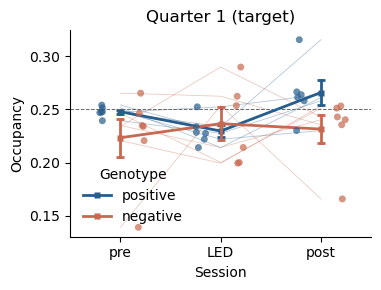

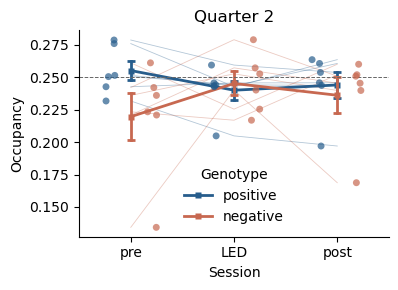

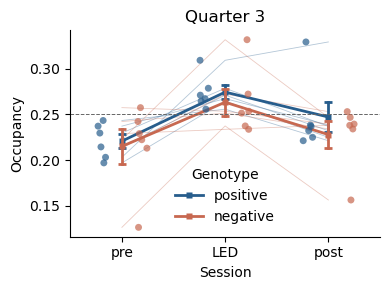

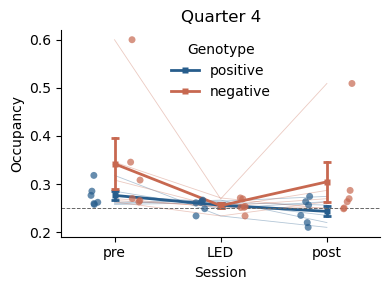

In [16]:
for quarter in QUARTERS:
    fig, ax = plt.subplots(figsize=(4, 3))
    plot_genotype_metric(result, "Occupancy", quarter=quarter, ax=ax)
    fig.tight_layout()
    
    plt.show()


## Other quarters

Occupancy is compositional: an increase in one quarter is balanced by a
decrease elsewhere. Color identifies genotype in every panel. Faint lines
connect each fish's sessions; thick lines show genotype means with SEM.
The 25% reference reflects equal area, not a behavioral null model.


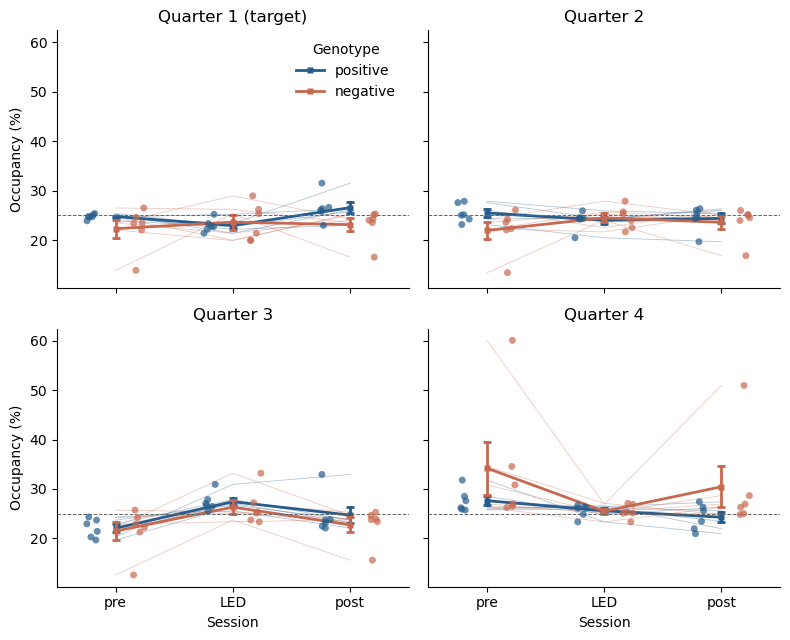

In [17]:
figure, axes = plt.subplots(2, 2, figsize=(8, 6.5), sharex=True, sharey=True)
for quarter, axis in zip(QUARTERS, axes.flat):
    plot_genotype_metric(
        table, "Occupancy", quarter=quarter, ax=axis,
        as_percent=True, show_legend=quarter == 1,
    )
figure.tight_layout()
plt.show()


## Interpretation and optional exports

An increase/decrease during LED is descriptive evidence for altered target
occupancy. Without control/sham fish, it cannot establish whether light,
session order, adaptation, or time caused that change. The three session
labels come from your input mapping. This notebook does not establish actual
light delivery; use `opto.h5` and the uploaded guide for hardware timing.

Formal tests should treat fish as repeated biological replicates, with planned
paired contrasts or a repeated-measures model appropriate to the design.
No significance test is selected automatically without the sample size and
control design. Raw recordings are opened read-only.

Uncomment exports below if you want derived files. Keep the code and CONFIG
with the results for reproducibility.


In [ ]:
# output = Path("occupancy_results")
# output.mkdir(exist_ok=True)
# table.to_csv(output / "quarter_occupancy.csv", index=False)
# qc.to_csv(output / "session_qc.csv", index=False)
# changes.to_csv(output / "target_paired_changes.csv")
# figure.savefig(output / "all_quarters.pdf", bbox_inches="tight")


In [18]:
bout_columns = [
    "Fish ID", "Genotype", "Quarter", "Session", "Swim bout count",
    "Swim bout rate (per min)", "Bout-observable time (s)",
    "Bout observation coverage", "Swim-active time (s)", "Swim fraction",
    "Complete bout count", "Mean bout duration (s)",
    "Left-censored bout fragments", "Right-censored bout fragments", "Bout status",
]
display(table[bout_columns])
display(bout_table)


,Fish ID,Genotype,Quarter,Session,Swim bout count,Swim bout rate (per min),Bout-observable time (s),Bout observation coverage,Swim-active time (s),Swim fraction,Complete bout count,Mean bout duration (s),Left-censored bout fragments,Right-censored bout fragments,Bout status
0,10290,positive,1,pre,33,19.078152,103.783638,0.229330,12.524506,0.120679,15,0.189095,108,121,ok
1,10290,positive,2,pre,47,29.520336,95.527368,0.218656,12.754233,0.133514,14,0.256813,116,144,ok
2,10290,positive,3,pre,49,33.174576,88.622083,0.214446,10.464294,0.118078,9,0.264327,103,137,ok
3,10290,positive,4,pre,62,38.027236,97.824621,0.196674,18.249362,0.186552,13,0.387548,197,242,ok
4,10290,positive,1,LED,34,35.721455,57.108536,0.148190,8.196916,0.143532,10,0.167594,105,126,ok
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,10302,negative,4,LED,20,3.935124,304.945937,0.816285,4.720759,0.015481,4,0.212469,20,28,ok
140,10302,negative,1,post,15,2.760309,326.050489,0.839330,8.524004,0.026143,4,0.463323,24,26,ok
141,10302,negative,2,post,20,3.514004,341.490817,0.820776,9.538212,0.027931,1,0.466987,27,39,ok
142,10302,negative,3,post,8,1.564589,306.789750,0.819194,3.732709,0.012167,2,0.671204,8,10,ok


,Fish ID,Session,Bout ID,Quarter,First observed quarter,Onset time (s),First active time (s),Offset time (s),Duration (s),Left censored,Right censored,N observations,Time field,File,Genotype
0,10290,pre,1,NaN,4,NaN,16.518094,NaN,NaN,True,True,6,time_s,E:\Open Field\Square OF\Dat-CoChr Positive\102...,positive
1,10290,pre,2,NaN,3,NaN,16.974019,NaN,NaN,True,True,4,time_s,E:\Open Field\Square OF\Dat-CoChr Positive\102...,positive
2,10290,pre,3,NaN,1,NaN,29.083943,NaN,NaN,True,True,4,time_s,E:\Open Field\Square OF\Dat-CoChr Positive\102...,positive
3,10290,pre,4,NaN,1,NaN,29.434489,NaN,NaN,True,True,2,time_s,E:\Open Field\Square OF\Dat-CoChr Positive\102...,positive
4,10290,pre,5,NaN,1,NaN,37.303777,NaN,NaN,True,True,3,time_s,E:\Open Field\Square OF\Dat-CoChr Positive\102...,positive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15133,10302,post,123,NaN,2,NaN,1571.950332,1572.282287,NaN,True,False,12,time_s,E:\Open Field\Square OF\Dat-CoChr Negative\103...,negative
15134,10302,post,124,2.0,2,1572.646096,1572.646096,NaN,NaN,False,True,2,time_s,E:\Open Field\Square OF\Dat-CoChr Negative\103...,negative
15135,10302,post,125,NaN,2,NaN,1572.760775,NaN,NaN,True,True,7,time_s,E:\Open Field\Square OF\Dat-CoChr Negative\103...,negative
15136,10302,post,126,NaN,2,NaN,1572.997737,1573.230859,NaN,True,False,8,time_s,E:\Open Field\Square OF\Dat-CoChr Negative\103...,negative


In [19]:
bout_changes = {}
for metric in [
    "Swim bout count", "Swim bout rate (per min)",
    "Swim fraction", "Mean bout duration (s)",
]:
    wide = table.pivot(
        index=["Genotype", "Fish ID", "Quarter"], columns="Session", values=metric
    ).reindex(columns=SESSIONS)
    changes_for_metric = pd.DataFrame({
        "LED - pre": wide["LED"] - wide["pre"],
        "post - pre": wide["post"] - wide["pre"],
        "post - LED": wide["post"] - wide["LED"],
    })
    if metric == "Swim fraction":
        changes_for_metric *= 100
    bout_changes[metric] = changes_for_metric
    print(metric + (" (percentage-point changes)" if metric == "Swim fraction" else ""))
    display(changes_for_metric)


Swim bout count


LED - pre  post - pre  post - LED
Genotype Fish ID Quarter                                   
positive 10290   1                1          24          23
                 2              -22           8          30
                 3              -17         -10           7
                 4              -40         -21          19
         10292   1               15         -18         -33
                 2              -48         -59         -11
                 3              -14         -41         -27
                 4              -23         -63         -40
         10293   1               10          32          22
                 2                2          17          15
                 3                3          58          55
                 4                4          25          21
         10294   1                3           7           4
                 2               -9          -8           1
                 3                1          -4          -5
                 4               -3         -13         -10
         10295   1                1           1           0
                 2                0           9           9
                 3                2           5           3
                 4                0           5           5
         10296   1               36         -26         -62
                 2              -10         -48         -38
                 3               57         -13         -70
                 4               -4         -33         -29
negative 10297   1              111         -11        -122
                 2               19          -6         -25
                 3               98          -5        -103
                 4               41           9         -32
         10298   1               12           1         -11
                 2                2           0          -2
                 3                2           3           1
                 4                5           1          -4
         10299   1              -43        -164        -121
                 2              -52        -149         -97
                 3              -45        -166        -121
                 4              -49        -177        -128
         10300   1              204          -8        -212
                 2              182          -3        -185
                 3              161           0        -161
                 4              176          -4        -180
         10301   1               61         -21         -82
                 2               14         -32         -46
                 3               23         -25         -48
                 4               26         -25         -51
         10302   1              -32         -98         -66
                 2             -132        -132           0
                 3              -99        -115         -16
                 4             -119        -126          -7

Swim bout rate (per min)


LED - pre  post - pre  post - LED
Genotype Fish ID Quarter                                   
positive 10290   1        16.643303   39.819915   23.176612
                 2        -1.847764   24.351387   26.199151
                 3        -5.153046   15.974590   21.127637
                 4       -12.128706    1.018983   13.147689
         10292   1        32.657794   -3.171538  -35.829332
                 2         2.721149   15.840219   13.119070
                 3         9.495947   15.916001    6.420054
                 4        16.063202   -8.764281  -24.827483
         10293   1        42.077949   21.052356  -21.025593
                 2         8.841972   13.716376    4.874404
                 3        10.208043   18.167371    7.959328
                 4        12.513287   13.020140    0.506853
         10294   1        26.441129   14.613695  -11.827435
                 2        13.063404    9.331573   -3.731832
                 3        29.544687   -0.093327  -29.638014
                 4        39.661970  -10.904160  -50.566130
         10295   1        28.169722   -0.572828  -28.742550
                 2         0.000000   19.650550   19.650550
                 3        30.978578   13.182692  -17.795887
                 4         7.920246    9.850565    1.930320
         10296   1         8.145674   -2.689058  -10.834732
                 2         1.145425   -2.696601   -3.842027
                 3         4.581557   -1.636735   -6.218292
                 4         2.921292   -0.179274   -3.100566
negative 10297   1        26.060989   -2.321156  -28.382145
                 2         3.771621   -1.837975   -5.609596
                 3        11.594772   -1.596788  -13.191560
                 4         7.514023    1.822552   -5.691471
         10298   1         2.532884    0.147947   -2.384936
                 2         0.435503    0.000000   -0.435503
                 3         0.293236    0.674437    0.381201
                 4         1.077303    0.093400   -0.983903
         10299   1        -6.597516  -32.320877  -25.723361
                 2       -14.237154  -29.004526  -14.767372
                 3        -8.831194  -29.762839  -20.931645
                 4        -8.281043  -30.563987  -22.282945
         10300   1        40.643056   -1.284408  -41.927464
                 2        36.390278   -0.656643  -37.046920
                 3        35.550835   -0.121532  -35.672366
                 4        36.264364   -0.803757  -37.068122
         10301   1        13.375272   -4.277645  -17.652917
                 2         1.099633   -6.488544   -7.588177
                 3         2.034294   -5.440630   -7.474923
                 4         4.955234   -3.052220   -8.007454
         10302   1        -7.552204  -18.052350  -10.500146
                 2       -20.984938  -21.682910   -0.697972
                 3       -17.405992  -20.334510   -2.928518
                 4       -18.858398  -20.548193   -1.689796

Swim fraction (percentage-point changes)


LED - pre  post - pre  post - LED
Genotype Fish ID Quarter                                   
positive 10290   1         2.285323    6.792273    4.506950
                 2        -5.156022    6.276024   11.432046
                 3        -4.639087    1.837890    6.476977
                 4        -9.966774   -5.770939    4.195835
         10292   1        19.624368   -0.563864  -20.188232
                 2        -1.995747    2.568196    4.563944
                 3         3.804681   -1.816437   -5.621118
                 4         6.984593   -8.793534  -15.778127
         10293   1        17.712664   19.553705    1.841042
                 2        -0.020776   11.684905   11.705681
                 3         1.706370   10.693237    8.986867
                 4         2.764509   11.853862    9.089353
         10294   1        12.174723    6.044614   -6.130109
                 2         8.703576   -1.576863  -10.280439
                 3         9.404465    3.210290   -6.194175
                 4         5.111345    1.052773   -4.058572
         10295   1         7.503415    1.073716   -6.429699
                 2        -3.683549    6.275113    9.958662
                 3         2.524378    7.171493    4.647115
                 4        -1.104950    3.300818    4.405768
         10296   1       -10.318825  -10.874287   -0.555462
                 2       -11.141585   -8.680396    2.461189
                 3        -8.674730   -6.738150    1.936580
                 4        -7.793320   -3.425478    4.367842
negative 10297   1        18.356257   -1.657560  -20.013817
                 2         0.678015   -1.161717   -1.839732
                 3         5.737495   -0.889075   -6.626570
                 4         2.133048    1.641697   -0.491351
         10298   1         1.380597    0.194982   -1.185615
                 2         0.142150   -0.167037   -0.309187
                 3        -0.004269    0.072700    0.076969
                 4         0.366175    0.022090   -0.344085
         10299   1        -8.266099  -23.141548  -14.875449
                 2       -12.221688  -19.711797   -7.490109
                 3        -8.415962  -21.405906  -12.989944
                 4        -9.349954  -21.614930  -12.264977
         10300   1        34.125236   -0.912497  -35.037734
                 2        34.384975   -0.543114  -34.928089
                 3        32.591285   -0.017797  -32.609082
                 4        34.069584   -0.440955  -34.510538
         10301   1         8.711436   -4.005659  -12.717095
                 2        -0.133894   -5.137920   -5.004026
                 3         0.395966   -4.524335   -4.920301
                 4         2.785751   -2.165643   -4.951394
         10302   1       -14.988923  -20.071399   -5.082476
                 2       -24.045275  -22.840039    1.205236
                 3       -17.759893  -19.881470   -2.121576
                 4       -21.241980  -21.346285   -0.104305

Mean bout duration (s)


LED - pre  post - pre  post - LED
Genotype Fish ID Quarter                                   
positive 10290   1        -0.021501    0.000965    0.022466
                 2        -0.153497    0.027630    0.181127
                 3        -0.170641         NaN         NaN
                 4         0.555966   -0.213140   -0.769106
         10292   1        -0.037967         NaN         NaN
                 2        -0.094737         NaN         NaN
                 3         0.087023   -0.116205   -0.203228
                 4        -0.225884   -0.314992   -0.089108
         10293   1              NaN         NaN         NaN
                 2              NaN         NaN         NaN
                 3              NaN         NaN         NaN
                 4              NaN         NaN    0.349079
         10294   1              NaN    0.216894         NaN
                 2              NaN         NaN         NaN
                 3              NaN         NaN         NaN
                 4              NaN         NaN         NaN
         10295   1              NaN         NaN         NaN
                 2              NaN         NaN         NaN
                 3              NaN         NaN         NaN
                 4              NaN         NaN         NaN
         10296   1        -0.354983   -0.205253    0.149730
                 2        -0.405304   -0.240358    0.164946
                 3        -0.459625   -0.265667    0.193958
                 4        -0.309672   -0.136463    0.173209
negative 10297   1        -0.034765   -0.104088   -0.069323
                 2        -0.157220   -0.006271    0.150949
                 3        -0.197540   -0.071982    0.125558
                 4        -0.104934    0.130365    0.235299
         10298   1              NaN         NaN   -0.066887
                 2              NaN         NaN         NaN
                 3              NaN         NaN    0.218196
                 4              NaN         NaN    0.210046
         10299   1        -0.037540    0.236551    0.274091
                 2        -0.076168    0.035635    0.111803
                 3        -0.003906    0.128887    0.132793
                 4        -0.064621    0.096695    0.161316
         10300   1        -0.069400         NaN         NaN
                 2        -0.251925    0.034749    0.286674
                 3        -0.149871    0.115134    0.265005
                 4        -0.162449    0.045453    0.207902
         10301   1        -0.146852    0.053821    0.200673
                 2        -0.197138         NaN         NaN
                 3        -0.075956    0.095155    0.171111
                 4         0.055208    0.048398   -0.006810
         10302   1        -0.068758    0.093192    0.161950
                 2        -0.213233    0.049258    0.262491
                 3        -0.085144    0.292877    0.378021
                 4        -0.166003   -0.041083    0.124920

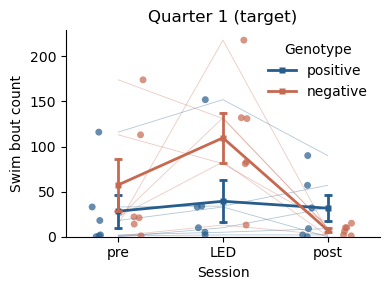

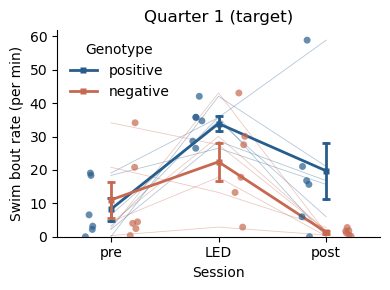

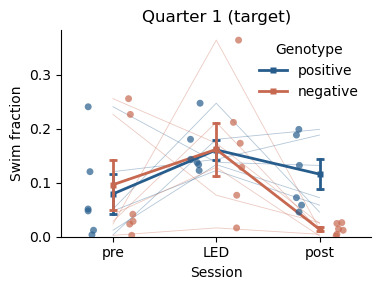

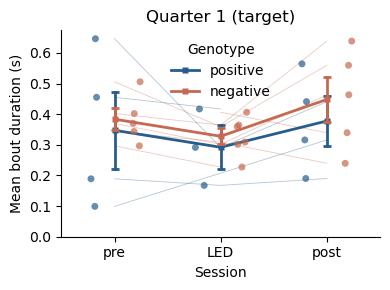

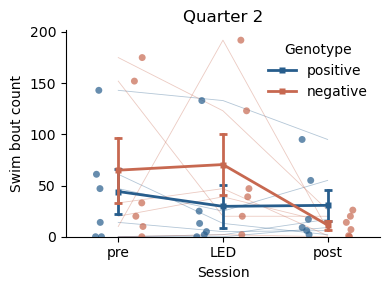

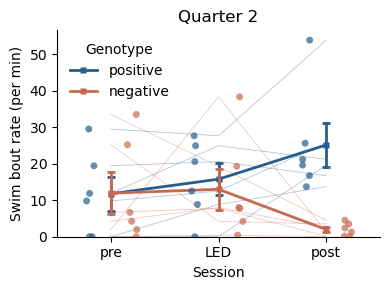

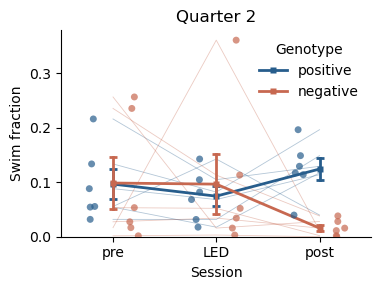

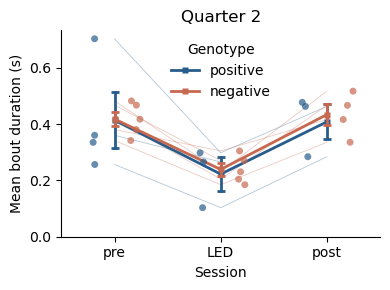

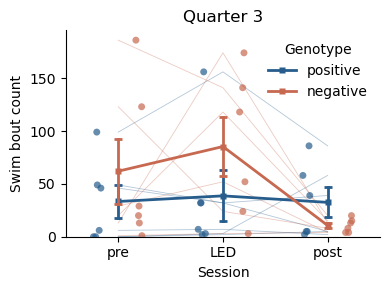

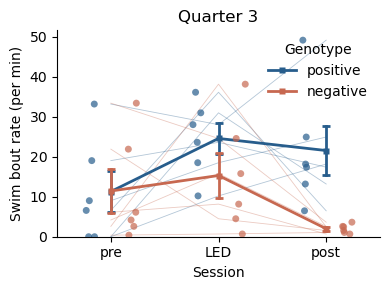

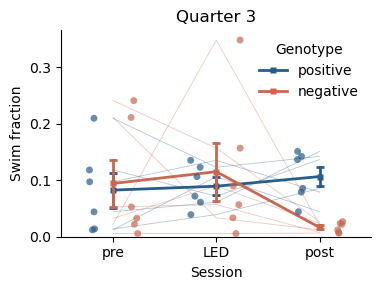

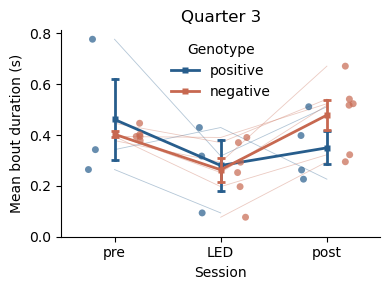

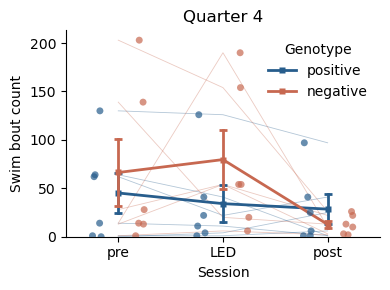

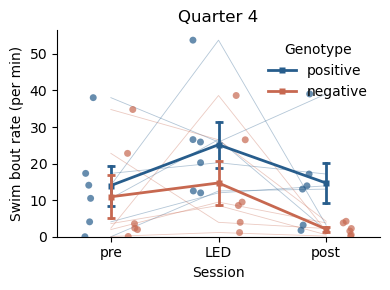

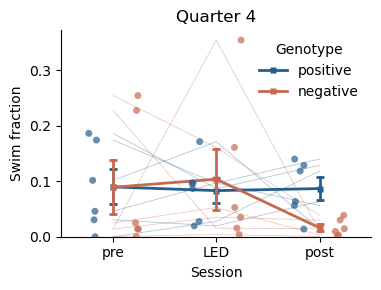

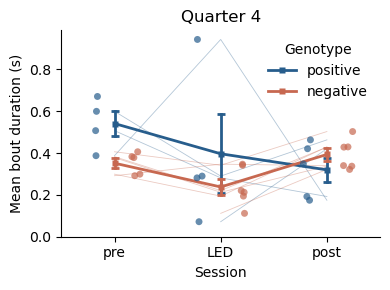

In [ ]:
for quarter in QUARTERS:
    for metric in [
        #"Swim bout count", 
        "Swim bout rate (per min)",
        "Swim fraction", 
        #"Mean bout duration (s)",
    ]:
        fig, ax = plt.subplots(figsize=(4, 3))
        plot_genotype_metric(result, metric, quarter=quarter, ax=ax)
        fig.tight_layout()
        plt.show()
